In [1]:
from IPython.display import HTML
import math
import random
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
def f(x):
    return 3*x**2 - 4*x + 5
f(3.0)

20.0

input xs are=[-6.   -5.75 -5.5  -5.25 -5.   -4.75 -4.5  -4.25 -4.   -3.75 -3.5  -3.25
 -3.   -2.75 -2.5  -2.25 -2.   -1.75 -1.5  -1.25 -1.   -0.75 -0.5  -0.25
  0.    0.25  0.5   0.75  1.    1.25  1.5   1.75  2.    2.25  2.5   2.75
  3.    3.25  3.5   3.75  4.    4.25  4.5   4.75  5.    5.25  5.5   5.75]
output ys are=[137.     127.1875 117.75   108.6875 100.      91.6875  83.75    76.1875
  69.      62.1875  55.75    49.6875  44.      38.6875  33.75    29.1875
  25.      21.1875  17.75    14.6875  12.       9.6875   7.75     6.1875
   5.       4.1875   3.75     3.6875   4.       4.6875   5.75     7.1875
   9.      11.1875  13.75    16.6875  20.      23.6875  27.75    32.1875
  37.      42.1875  47.75    53.6875  60.      66.6875  73.75    81.1875]


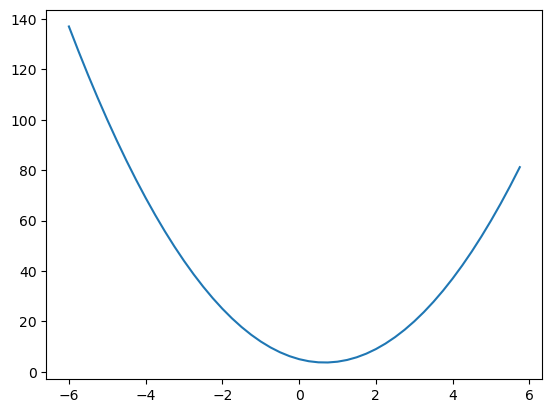

In [60]:
xs = np.arange(-6,6,0.25)
print(f'input xs are={xs}')
ys = f(xs)
print(f'output ys are={ys}')
plt.plot(xs,ys)

In [61]:
# simple value object

# the __repr__ function is helping in printing out the values properly, without it we would get hex numbers when printing
class Value:
    def __init__(self, data, _children=(), _op ='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label
        
    def __repr__(self):
        return f"Value(data={self.data})"
        
    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, _children = (self, other), _op = '+') 
        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out
        
    def __mul__(self, other):
        other = other if isinstance(other,Value) else Value(other)
        out = Value(self.data * other.data, _children = (self, other), _op = '*')
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data**other, (self,), f'**{other}')
        def _backward():
            self.grad +=  other * (self.data ** (other - 1)) * out.grad
            
        out._backward = _backward
        return out

    def __radd__(self, other): # for number + Value
        return self + other
    
    def __rmul__(self, other):    # other * self (swaps the order)
        return self * other

    def __truediv__(self, other):  # self / other
        return self * other**-1

    def __neg__(self):
        return self * -1 # - self

    def __sub__(self, other):  # self - other
        return self + (- other)
    
    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t,(self, ),'tanh')
        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x),(self,), 'exp')

        def _backward():
            self.grad += out.data * out.grad 
        out._backward = _backward
        return out
        
    def backward(self):
        # made the topological list
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0 # set the output grad to 1
        # go from the reversed order of the topological list
        for node in reversed(topo):
            node._backward()
            

In [62]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges
def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})  # LR = left to right

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')

        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name=uid + n._op, label=n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

In [63]:
# building neural networks for our micrograds -- Value objects
class Neuron:

    def __init__(self, nin): # takes in self and number of inputs to that specific neuron
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        # print("weights ", self.w, "\n")
        self.b = Value(random.uniform(-1,1))
        # print("bias ", self.b, "\n")

    def __call__(self, x):
        # w * x + b
        # print("ziping ", list(zip(self.w, x))) # iterates over the tuples of the two iterators corresponding entries
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b) # sum can take in a second parameter, by default its 0.0 but we can just add the bias at the srart for efficiency
        out = act.tanh()
        # print("calculated the forward pass ",out)
        return out

    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self, nin, nout):  # (each neurons dimension, how many of them I want)
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x
        
    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]


In [81]:
# initializing the neural network
x = [2.0, 3.0, -1.0]
n = MLP(3, [4, 4, 1]) # we want 3 inputs going into ---> 2 layers of 4 and an output unit
n(x)

Value(data=-0.0375824051689012)

In [82]:
# initializing the inputs
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, 1.0]
]
ys = [1.0, -1.0, -1.0, 1.0]

In [96]:
# calculating loss -- the whole gradient descent algorithm
for k in range(20): 
    # forward pass
    ypred = [n(x) for x in xs]
    loss = sum([(yout - ygt)**2 for ygt, yout in zip(ys, ypred)])

    # backward pass
    for p in n.parameters():
        p.grad = 0.0 # always need to reset the gradients to zero for each backward pass
    loss.backward()

    # update
    for p in n.parameters():
        p.data += - 0.05 * p.grad

    print(f'iteration {k} -- loss {loss.data}')


iteration 0 -- loss 0.00915388786969762
iteration 1 -- loss 0.009059143505576864
iteration 2 -- loss 0.008966266018785486
iteration 3 -- loss 0.00887520148835554
iteration 4 -- loss 0.008785898036124212
iteration 5 -- loss 0.008698305731298992
iteration 6 -- loss 0.008612376500308879
iteration 7 -- loss 0.008528064041604107
iteration 8 -- loss 0.008445323745091
iteration 9 -- loss 0.00836411261591049
iteration 10 -- loss 0.008284389202290545
iteration 11 -- loss 0.008206113527220674
iteration 12 -- loss 0.0081292470237151
iteration 13 -- loss 0.008053752473446892
iteration 14 -- loss 0.007979593948550504
iteration 15 -- loss 0.00790673675640366
iteration 16 -- loss 0.007835147387212651
iteration 17 -- loss 0.007764793464236704
iteration 18 -- loss 0.007695643696497967
iteration 19 -- loss 0.007627667833833517


In [97]:
ypred # final predictions

[Value(data=0.9900759156052304),
 Value(data=-0.9634961414648047),
 Value(data=-0.9485059314997276),
 Value(data=0.9404600167610814)]

In [98]:
n.parameters() # model settings that 

[Value(data=0.5573843205677657),
 Value(data=1.8070272904484614),
 Value(data=-0.3416027846969084),
 Value(data=-1.0985198034971104),
 Value(data=-1.9234166957200258),
 Value(data=-0.22399459367488928),
 Value(data=0.462356165680944),
 Value(data=1.009429584738716),
 Value(data=1.486878639417528),
 Value(data=-1.068884781634449),
 Value(data=-0.10475060435934708),
 Value(data=0.2843233150155786),
 Value(data=0.11977927986542276),
 Value(data=-0.05297502898802717),
 Value(data=0.5317177880868607),
 Value(data=0.9533189285648944),
 Value(data=-0.45896303148251855),
 Value(data=-0.11477727899806887),
 Value(data=-1.0788299945028847),
 Value(data=0.5124208164171425),
 Value(data=0.42699932492550585),
 Value(data=-1.0291933486838432),
 Value(data=0.7432276316378846),
 Value(data=-0.8217442956745182),
 Value(data=0.6504113725153922),
 Value(data=0.3126067593802142),
 Value(data=1.071011396674471),
 Value(data=-1.1177048182847773),
 Value(data=-0.050665822928197754),
 Value(data=0.19326000135

In [99]:
dot = draw_dot(loss)
svg = dot.pipe(format='svg').decode('utf-8')

HTML(f"""
<div style="
    width: 100%;
    height: 800px;
    overflow: auto;
">
    <div style="width: 4000px;">
        {svg}
    </div>
</div>
""")